# 10.1.1 Escoamento horizontal estratificado

Duto horizontal de 1000 m e 0.1 m de diâmetro, 50 elementos finitos (Galerkin), modelo a
dois fluidos (4 equações) com fechamento de padrão estratificado. $q_L = 0.5$ kg/s constante;
$q_G$ sobe de 0.1 para 0.13 kg/s em rampa entre 150 s e 180 s; pressão de saída 100 bar;
vazões impostas na entrada e pressão imposta na saída. Figuras 10.2 a 10.8 e Tabela 10.1.

Os resultados originais do MATLAB (`CASO10-1-1.mf2`) são sobrepostos a tracejado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thesis.notebook_utils import thesis_run, compare_states, show_pipe, plot_elements, plot_vertices
from thesis.mf2 import legacy_pipe_dict
from mfsim.plotting import pipe_profiles, compare_runs
from mfsim.runs import load_run

run, res, raw = thesis_run("10.1.1")
compare_states(res, raw)

10.1.1 Escoamento horizontal estratificado
Duto horizontal de 1000 m, D=0.1 m, 50 elementos, Galerkin, modelo a 4 equações com padrão estratificado fixo. qL=0.5 kg/s; qG sobe de 0.1 para 0.13 kg/s entre 150 e 180 s. Pressão de saída 100 bar.
Figuras da tese: Figs. 10.2-10.8, Tabela 10.1
corrida 10_1_1.npz: integrador bdf (rtol 0.001, atol 0.001, max_step 1.0), 301 instantes de saída até 3000 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 twofluid     alphaG    2.70e-05       5.64e-02   4.79e-04
   1 twofluid     PT        2.03e-06       4.22e-04   4.80e-03
   1 twofluid     qL        4.29e-04       1.46e-01   2.94e-03
   1 twofluid     qG        1.44e-04       3.00e-02   4.80e-03


## Condições iniciais (Figura 10.2)
O estado inicial é o gravado pelo MATLAB (`estados.X[:, 0]`, ver [issue 001](../../docs/issues/001-reproducao-capitulo-10.md)).

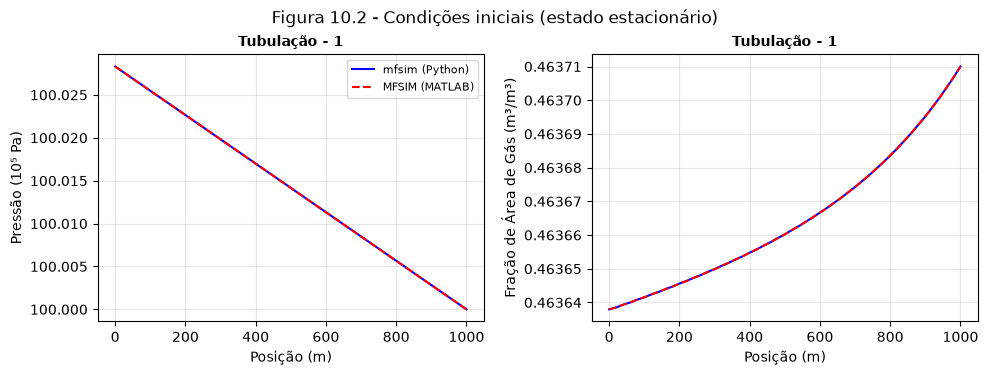

In [2]:
fig = pipe_profiles(res, keys=("P_bar", "alphaG"), it=0, legacy=legacy_pipe_dict(raw, 0))
fig.suptitle("Figura 10.2 - Condições iniciais (estado estacionário)", y=1.03)
plt.show()

## Simulação dinâmica (Figura 10.3) e comparação com o MATLAB em três posições

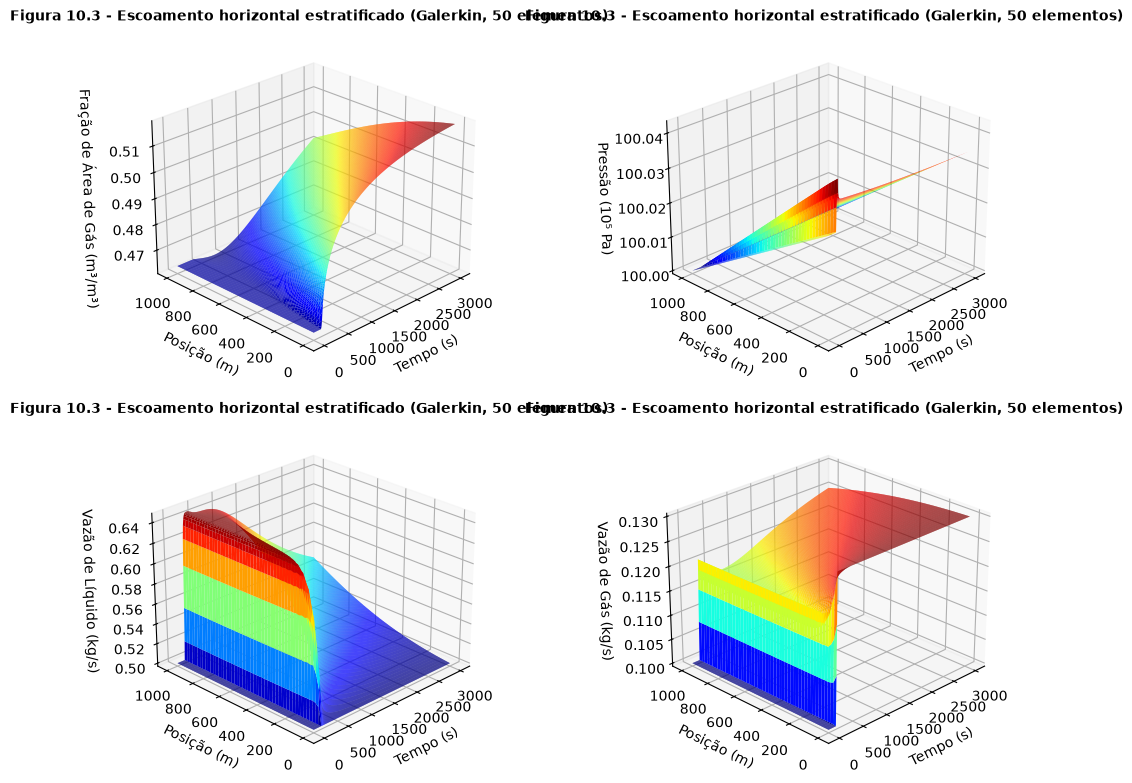

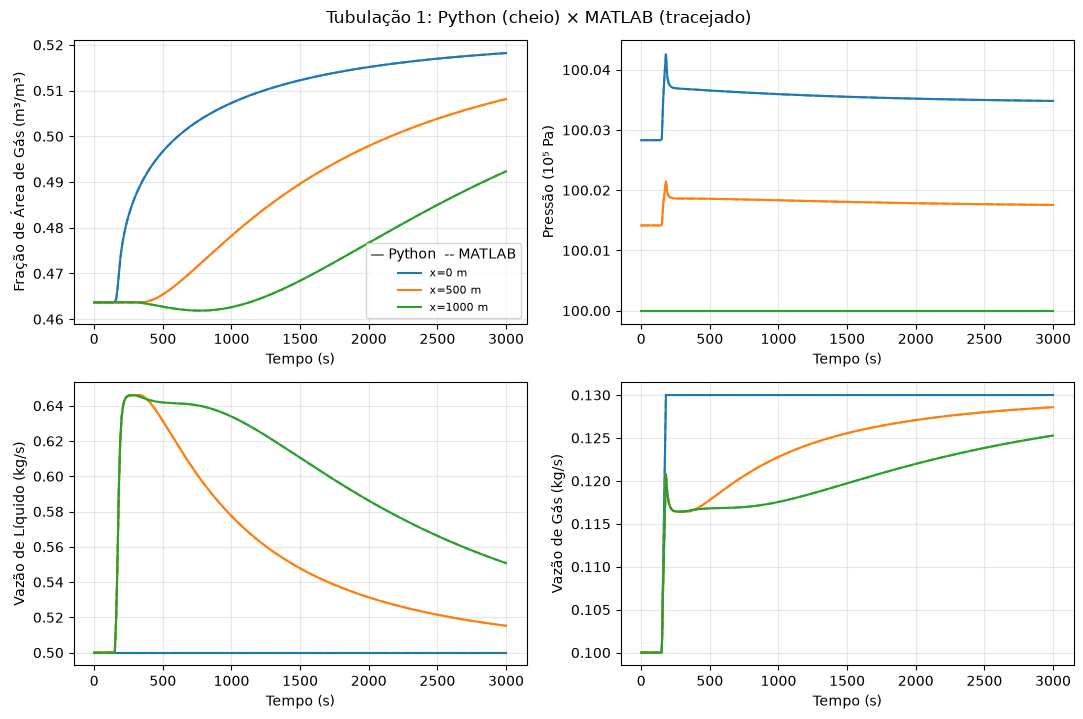

In [3]:
show_pipe(res, raw, 0, title="Figura 10.3 - Escoamento horizontal estratificado (Galerkin, 50 elementos)")

## Sensibilidade de malha (Figuras 10.4 e 10.5)

Para cada malha o estado estacionário é recalculado e a simulação repetida, com o esquema
de Galerkin e com diferenças finitas centrais (corridas `10_1_1_<esquema>_n<N>` do lote).

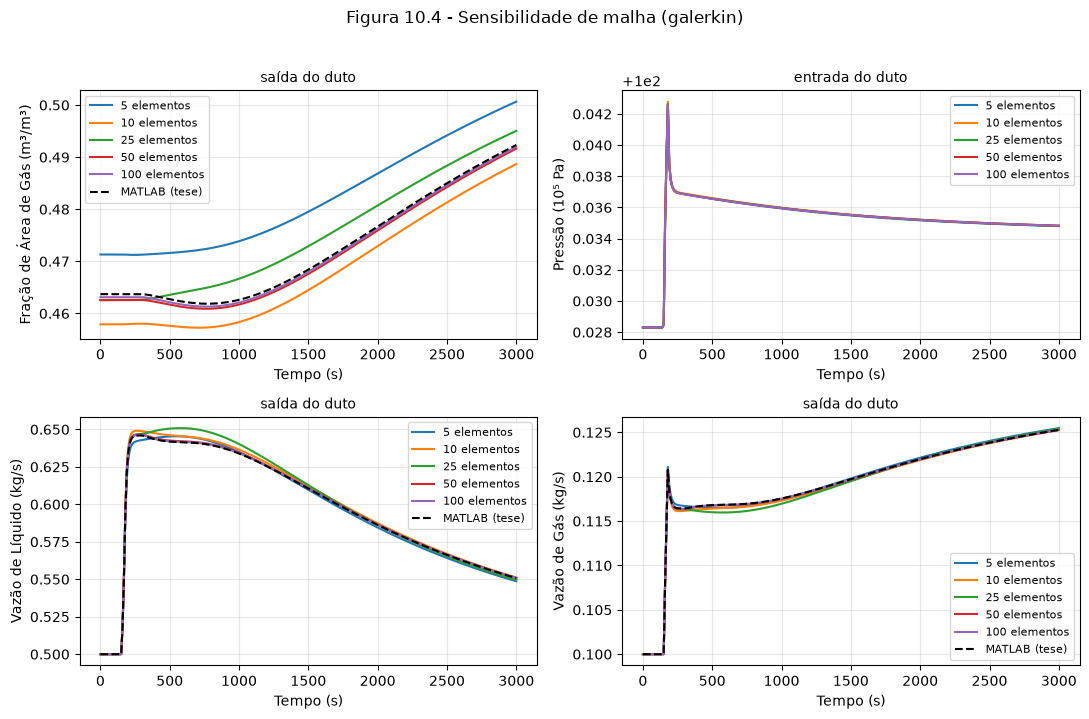

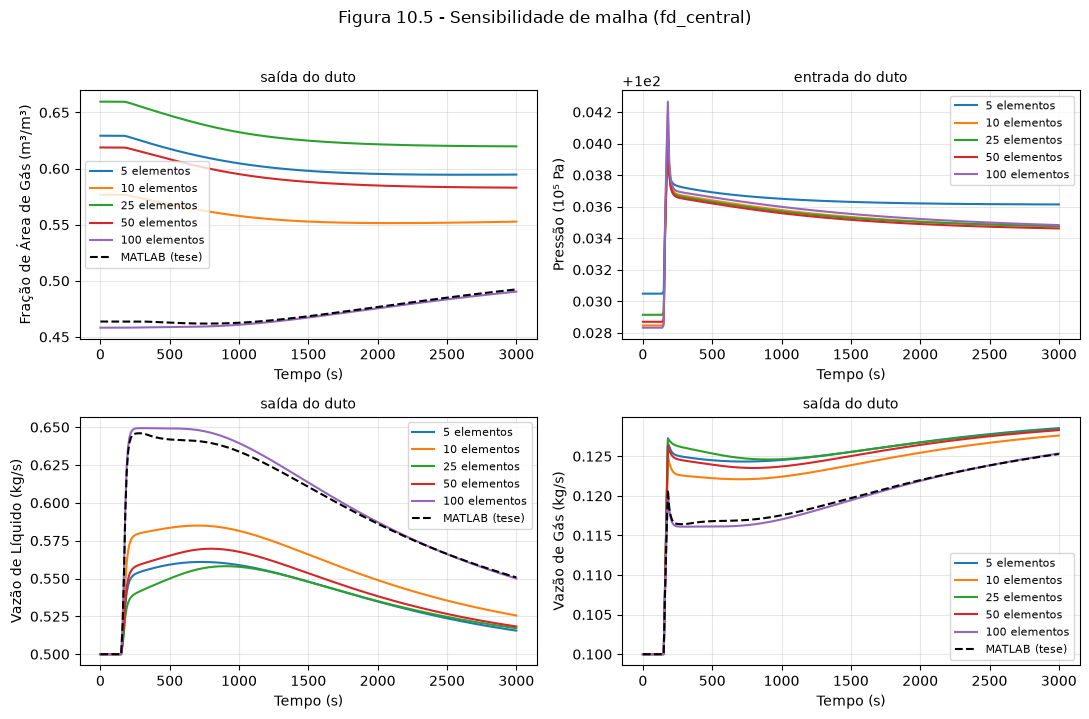

In [4]:
legacy = legacy_pipe_dict(raw, 0)
meshes = [5, 10, 25, 50, 100]
for scheme, fig_no in (("galerkin", "10.4"), ("fd_central", "10.5")):
    runs = {f"{n} elementos": load_run(f"chapter10/10_1_1_{scheme}_n{n}").res for n in meshes}
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ax, k_ in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
        compare_runs(
            runs,
            key=k_,
            node=-1 if k_ != "P_bar" else 0,
            ax=ax,
            legacy=legacy if k_ != "P_bar" else None,
            title=f"{'saída' if k_ != 'P_bar' else 'entrada'} do duto",
        )
    fig.suptitle(f"Figura {fig_no} - Sensibilidade de malha ({scheme})", y=1.02)
    fig.tight_layout()
    plt.show()

## Galerkin × diferenças finitas (Figura 10.6) e Tabela 10.1

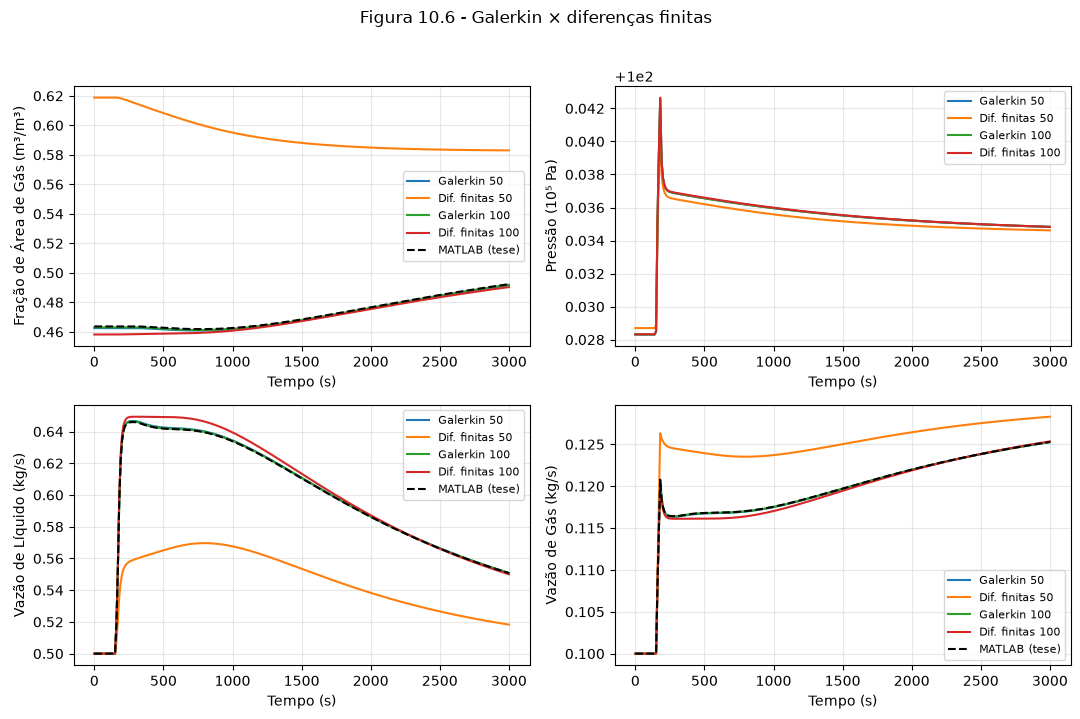

Tabela 10.1 - custo (estado estacionário + simulação, BDF do SciPy)
Método           N      CPU
galerkin         5    3.25s
galerkin        10    4.16s
galerkin        25    6.70s
galerkin        50   11.22s
galerkin       100   16.61s
fd_central       5    1.14s
fd_central      10    1.15s
fd_central      25    1.21s
fd_central      50    1.27s
fd_central     100    1.43s


In [5]:
sel = {
    "Galerkin 50": "galerkin_n50",
    "Dif. finitas 50": "fd_central_n50",
    "Galerkin 100": "galerkin_n100",
    "Dif. finitas 100": "fd_central_n100",
}
runs6 = {lab: load_run(f"chapter10/10_1_1_{tag}") for lab, tag in sel.items()}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, k_ in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
    compare_runs(
        {lab: r.res for lab, r in runs6.items()},
        key=k_,
        node=-1 if k_ != "P_bar" else 0,
        ax=ax,
        legacy=legacy if k_ != "P_bar" else None,
    )
fig.suptitle("Figura 10.6 - Galerkin × diferenças finitas", y=1.02)
fig.tight_layout()
plt.show()

print("Tabela 10.1 - custo (estado estacionário + simulação, BDF do SciPy)")
print(f"{'Método':12s} {'N':>5s} {'CPU':>8s}")
for scheme in ("galerkin", "fd_central"):
    for n in meshes:
        r = load_run(f"chapter10/10_1_1_{scheme}_n{n}")
        print(f"{scheme:12s} {n:5d} {r.info.get('cpu_total', float('nan')):7.2f}s")

---
*Notebook de reprodução fiel: nenhuma simulação corre aqui. As corridas vêm do lote
`batches/thesis.json` (`uv run mfsim batch batches/thesis.json`), com a configuração exportada
do ficheiro original; as correções e melhorias estão nos notebooks de `notebooks_src/issues/`
e no índice [docs/issues/INDEX.md](../../docs/issues/INDEX.md).*